# Benchmark Multi-Model (Indonesia vs Umum/Multibahasa) — NER Lowongan Kerja Indonesia

Notebook ini melatih dan mengevaluasi model pralatih pada dataset dan pembagian
data yang sama persis dengan pipeline IndoBERT, sehingga angkanya dapat
dibandingkan langsung.

**Tujuan perbandingan:** melihat seberapa besar manfaat model khusus bahasa
Indonesia dibanding model yang lebih **umum** (multibahasa, tidak dilatih
khusus untuk bahasa Indonesia). Model umum boleh lebih buruk; yang diukur
adalah selisihnya.

| Kelompok | Model |
|---|---|
| Khusus bahasa Indonesia | `indolem/indobert-base-uncased` (model skripsi), `cahya/bert-base-indonesian-1.5G`, `indobenchmark/indobert-base-p2` |
| Umum / multibahasa | `bert-base-multilingual-cased` (mBERT, 104 bahasa), `distilbert-base-multilingual-cased` (versi ringkas mBERT) |

## Yang perlu dilampirkan lewat Add Data

1. `gold_annotations_dataset.json` — berkas anotasi
2. `splits.csv` — pembagian train/validation/test

Keduanya ada di repositori dataset. Memakai `splits.csv` penting: bila
pembagian dibuat ulang, angkanya tidak lagi sebanding dengan hasil IndoBERT.

## Perkiraan waktu

Model *base* sekitar 40–60 menit per model di GPU T4; DistilmBERT sekitar
setengahnya. Lima model ≈ 3,5–4,5 jam, masih di bawah batas sesi Kaggle.
Hasil tiap model langsung disimpan ke `outputs/hasil_benchmark.json`, jadi bila
sesi terputus, model yang sudah selesai tidak diulang.


## 1. Persiapan

In [1]:
# JANGAN memasang ulang paket yang sudah ada di Kaggle.
#
# Pemeriksaan memakai importlib.util.find_spec: hanya MENCARI apakah paket
# terpasang, TIDAK menjalankan/mengimpornya. Versi sebelumnya memakai
# import_module, sehingga "accelerate" ikut mengimpor torch di tengah
# pemeriksaan; bila impor itu tersendat, torch tertinggal setengah termuat dan
# muncul galat:
#     AttributeError: partially initialized module 'torch' has no attribute 'cuda'
#
# Bila galat itu masih muncul: menu Run -> Restart & Clear Cell Outputs,
# lalu jalankan lagi dari atas. Galat tersebut tidak hilang tanpa restart
# karena torch yang setengah termuat tetap tersimpan di memori kernel.

import importlib.util, subprocess, sys

perlu = [paket for modul, paket in [("transformers", "transformers"),
                                    ("datasets", "datasets"),
                                    ("accelerate", "accelerate"),
                                    ("sklearn", "scikit-learn")]
         if importlib.util.find_spec(modul) is None]

if perlu:
    print("Memasang yang belum ada:", perlu)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *perlu], check=False)
    print("\nPENTING: setelah pemasangan, MULAI ULANG KERNEL (Run -> Restart &")
    print("Clear Cell Outputs), lalu jalankan lagi dari atas.")
else:
    print("Semua paket sudah tersedia; tidak ada yang dipasang.")


Semua paket sudah tersedia; tidak ada yang dipasang.


In [2]:
# torch diimpor PALING AWAL dan sendiri, agar bila ada masalah pada torch,
# galat aslinya yang tampil -- bukan galat lanjutan dari paket lain.
import torch

import os, json, re, csv, gc, time, random
from collections import Counter

import numpy as np
import pandas as pd
import transformers

print("torch       ", torch.__version__)
print("transformers", transformers.__version__)
print("GPU         ", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "tidak ada")


torch        2.11.0+cu130
transformers 5.20.2
GPU          Tesla T4


## 2. Konfigurasi

Hiperparameter di bawah **sama persis** dengan pipeline IndoBERT. Jangan
diubah bila tujuannya membandingkan arsitektur model — kalau hiperparameternya
ikut berbeda, perbedaan skor tidak bisa dikaitkan ke modelnya.

In [3]:
class CFG:
    GOLD_JSON = None          # dicari otomatis di /kaggle/input
    SPLITS_CSV = None         # dicari otomatis di /kaggle/input
    OUTPUT_DIR = "outputs"
    TEXT_FIELD = "description"

    ENTITY_LABELS = [
        "JOB_TITLE", "COMPANY", "LOCATION", "EDUCATION_LEVEL", "DEGREE_FIELD",
        "EXPERIENCE_YEARS", "RESPONSIBILITY", "SKILL", "SOFT_SKILL", "TOOL",
        "PROGRAMMING_LANGUAGE", "INDUSTRY", "SALARY", "EMPLOYMENT_TYPE",
    ]

    # MAX_LEN dinaikkan dari 256 ke 384. Pada percobaan pertama, tokenizer
    # SentencePiece milik XLM-R memecah kata Indonesia menjadi lebih banyak
    # subkata, sehingga lebih banyak teks terpotong dan 65 span acuan hilang
    # (13.236 berbanding 13.301 pada IndoBERT). Akibatnya model dinilai pada
    # test set yang tidak sama persis. Dengan 384 seluruh chunk muat.
    MAX_LEN = 384
    CHUNK_WORDS = 180
    LR = 3e-5
    WARMUP_RATIO = 0.1
    EPOCHS = 40
    EARLY_STOP = 9
    BATCH_SIZE = 16
    WEIGHT_DECAY = 0.01
    SEED = 42
    # Seed tambahan untuk pengulangan. Kosongkan ([]) bila hanya ingin satu
    # kali jalan per model. Dipakai pada bagian 7.
    SEED_ULANG = [42, 1337, 2024]
    FP16 = True               # hemat memori & waktu di T4


# ---------------------------------------------------------------------------
# DAFTAR MODEL YANG DIUJI
#
# "jenis" dipakai di tabel hasil untuk membedakan model khusus bahasa
# Indonesia dengan model umum/multibahasa. Ubah "aktif" ke False untuk
# melewati model tertentu pada sesi ini.
#
#   indolem/indobert-base-uncased        model skripsi (pembanding dasar)
#   cahya/bert-base-indonesian-1.5G      BERT Indonesia, korpus Wikipedia+berita
#   indobenchmark/indobert-base-p2       IndoBERT versi IndoNLU
#   bert-base-multilingual-cased         mBERT: 104 bahasa, model umum klasik
#   distilbert-base-multilingual-cased   mBERT yang dipadatkan (6 lapis), lebih
#                                        ringan dan cepat
# ---------------------------------------------------------------------------
DAFTAR_MODEL = [
    {"nama": "indolem/indobert-base-uncased",      "batch": 16, "aktif": True, "jenis": "Khusus Indonesia"},
    {"nama": "cahya/bert-base-indonesian-1.5G",    "batch": 16, "aktif": True, "jenis": "Khusus Indonesia"},
    {"nama": "indobenchmark/indobert-base-p2",     "batch": 16, "aktif": True, "jenis": "Khusus Indonesia"},
    {"nama": "bert-base-multilingual-cased",       "batch": 16, "aktif": True, "jenis": "Umum (multibahasa)"},
    {"nama": "distilbert-base-multilingual-cased", "batch": 16, "aktif": True, "jenis": "Umum (multibahasa)"},
]
JENIS = {m["nama"]: m["jenis"] for m in DAFTAR_MODEL}

os.makedirs(CFG.OUTPUT_DIR, exist_ok=True)

IOB_LABELS = ["O"] + [f"{p}-{e}" for e in CFG.ENTITY_LABELS for p in ("B", "I")]
LABEL2ID = {l: i for i, l in enumerate(IOB_LABELS)}
ID2LABEL = {i: l for l, i in LABEL2ID.items()}
print(f"{len(IOB_LABELS)} label IOB2")


29 label IOB2


## 3. Muat data dan pembagiannya

In [4]:
import glob

# Tampilkan semua berkas yang terlampir. Berguna saat berkas tidak ditemukan:
# Kaggle sering mengubah namanya (spasi atau nomor tambahan).
print("Berkas di /kaggle/input:")
for akar, _, berkas in os.walk("/kaggle/input"):
    for b in berkas:
        print("  -", os.path.join(akar, b))
print()


def cari(pola_list, keterangan):
    """Cari berkas di /kaggle/input.

    Pola dibuat longgar karena Kaggle kerap mengubah nama berkas saat
    diunggah -- menyisipkan spasi ("splits .csv") atau menambah nomor
    ("splits (2).csv"). Pencocokan ketat akan gagal menemukannya.
    """
    for pola in pola_list:
        hit = sorted(glob.glob(pola, recursive=True))
        if hit:
            return hit[0]
    raise FileNotFoundError(
        f"{keterangan} tidak ditemukan.\n"
        "Klik 'Add Data' lalu lampirkan gold_annotations_dataset.json dan "
        "splits.csv dari repositori dataset.\n"
        f"Pola yang dicoba: {pola_list}")

CFG.GOLD_JSON = cari(["/kaggle/input/**/*gold*annotation*.json",
                      "/kaggle/input/**/*annotation*.json",
                      "/kaggle/input/**/*.json", "*annotation*.json"],
                     "Berkas anotasi")
print("Anotasi :", CFG.GOLD_JSON)

with open(CFG.GOLD_JSON, encoding="utf-8") as f:
    gold_data = json.load(f)
print(f"Dokumen dimuat: {len(gold_data):,}")

# ---------------------------------------------------------------------------
# Pembagian train/validation/test
#
# Kalau splits.csv dilampirkan, berkas itu yang dipakai -- cara paling aman.
# Kalau tidak ada, pembagian dibentuk ulang dengan prosedur yang sama persis
# seperti pipeline IndoBERT: train_test_split pada tingkat DOKUMEN, kunci
# berupa URL, seed 42, 15% test lalu 15% dari sisanya untuk validation.
#
# Hasilnya diverifikasi terhadap jumlah yang diharapkan. Bila tidak cocok,
# sel ini BERHENTI, karena angka yang dihasilkan tidak akan sebanding dengan
# hasil IndoBERT di naskah.
# ---------------------------------------------------------------------------
HARAPAN = {"train": 3699, "validation": 653, "test": 769}

try:
    CFG.SPLITS_CSV = cari(["/kaggle/input/**/splits*.csv",
                           "/kaggle/input/**/*split*.csv",
                           "splits*.csv"], "splits.csv")
    with open(CFG.SPLITS_CSV, encoding="utf-8") as f:
        SPLIT_BY_URL = {r["url"]: r["split"] for r in csv.DictReader(f)}
    print("Splits  :", CFG.SPLITS_CSV, "(dari berkas)")
except FileNotFoundError:
    from sklearn.model_selection import train_test_split
    print("Splits  : splits.csv tidak dilampirkan -- dibentuk ulang dengan seed 42")
    doc_ids = [d.get("url") for d in gold_data]
    if len(set(doc_ids)) != len(doc_ids):
        raise ValueError("Ada URL ganda; pembagian tidak dapat dibentuk ulang "
                         "secara andal. Lampirkan splits.csv.")
    tr, te = train_test_split(doc_ids, test_size=0.15, random_state=CFG.SEED)
    tr, va = train_test_split(tr, test_size=0.15, random_state=CFG.SEED)
    SPLIT_BY_URL = {}
    for u in tr: SPLIT_BY_URL[u] = "train"
    for u in va: SPLIT_BY_URL[u] = "validation"
    for u in te: SPLIT_BY_URL[u] = "test"
    # simpan agar dapat diunduh dan dilampirkan pada sesi berikutnya
    with open(f"{CFG.OUTPUT_DIR}/splits.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f); w.writerow(["doc_id", "split", "url"])
        for i, d in enumerate(gold_data, 1):
            w.writerow([i, SPLIT_BY_URL[d["url"]], d["url"]])
    print(f"          disimpan ke {CFG.OUTPUT_DIR}/splits.csv")

jml = Counter(SPLIT_BY_URL.values())
print("Pembagian:", dict(jml))
if dict(jml) != HARAPAN:
    raise ValueError(
        f"Pembagian TIDAK cocok dengan pipeline IndoBERT.\n"
        f"  diperoleh : {dict(jml)}\n"
        f"  diharapkan: {HARAPAN}\n"
        "Angka yang dihasilkan tidak akan sebanding dengan hasil di naskah. "
        "Lampirkan splits.csv dari repositori dataset.")
print("Pembagian cocok dengan pipeline IndoBERT.")


Berkas di /kaggle/input:
  - /kaggle/input/datasets/dzakyzidan/jobclassification/ALL_batches_gold_annotations (3).json
  - /kaggle/input/datasets/dzakyzidan/jobclassification/kbji_referensi_jabatan.csv
  - /kaggle/input/datasets/dzakyzidan/jobclassification/splits (2).json
  - /kaggle/input/datasets/dzakyzidan/jobclassification/splits.csv

Anotasi : /kaggle/input/datasets/dzakyzidan/jobclassification/ALL_batches_gold_annotations (3).json
Dokumen dimuat: 5,121
Splits  : /kaggle/input/datasets/dzakyzidan/jobclassification/splits.csv (dari berkas)
Pembagian: {'train': 3699, 'validation': 653, 'test': 769}
Pembagian cocok dengan pipeline IndoBERT.


## 4. Bersihkan span dan bangun penandaan IOB2

Bagian ini **disalin dari pipeline IndoBERT tanpa perubahan**. Tokenisasi,
perbaikan span yang tidak selaras, penghapusan duplikat, dan pemotongan
dokumen harus identik; kalau berbeda, perbandingan antar model menjadi tidak
sah.

In [5]:
def clean_document(doc):
    text = (doc.get("data", {}) or {}).get(CFG.TEXT_FIELD, "") or ""
    fixed, seen = [], set()
    for ga in doc.get("gold_annotations", []):
        lab = ga.get("label")
        if lab not in CFG.ENTITY_LABELS:
            continue
        s, e, t = ga.get("start"), ga.get("end"), ga.get("text", "")
        if not text or s is None or e is None:
            continue
        if text[s:e] != t:                       # tidak selaras -> cari ulang
            pos = text.find(t)
            if pos < 0:
                continue
            s, e = pos, pos + len(t)
        if (s, e, lab) in seen:
            continue
        seen.add((s, e, lab))
        fixed.append({"start": s, "end": e, "text": text[s:e], "label": lab})
    return text, fixed


TOKEN_RE = re.compile(r"\w+|[^\w\s]", re.UNICODE)

def spans_to_iob(text, spans):
    toks = [(m.group(), m.start(), m.end()) for m in TOKEN_RE.finditer(text)]
    tags = ["O"] * len(toks)
    occupied = [False] * len(toks)
    for sp in sorted(spans, key=lambda s: (s["start"], -(s["end"] - s["start"]))):
        s, e, lab = sp["start"], sp["end"], sp["label"]
        idxs = [i for i, (t, ts, te) in enumerate(toks)
                if ts < e and te > s and not occupied[i]]
        if not idxs:
            continue
        for j, i in enumerate(idxs):
            tags[i] = ("B-" if j == 0 else "I-") + lab
            occupied[i] = True
    return [t[0] for t in toks], tags


def chunk_document(tokens, tags, max_tokens=CFG.CHUNK_WORDS):
    chunks, cur_t, cur_l = [], [], []
    for tok, tag in zip(tokens, tags):
        cur_t.append(tok); cur_l.append(tag)
        if len(cur_t) >= max_tokens and tag == "O":
            chunks.append((cur_t, cur_l)); cur_t, cur_l = [], []
    if cur_t:
        chunks.append((cur_t, cur_l))
    return chunks


DATA = {"train": [], "validation": [], "test": []}
lewat = 0
for doc in gold_data:
    url = doc.get("url")
    bagian = SPLIT_BY_URL.get(url)
    if bagian is None:
        lewat += 1
        continue
    text, spans = clean_document(doc)
    if not text:
        continue
    tokens, tags = spans_to_iob(text, spans)
    for ct, cl in chunk_document(tokens, tags):
        if ct:
            DATA[bagian].append({"tokens": ct, "ner_tags": cl})

if lewat:
    print(f"PERINGATAN: {lewat} dokumen tidak ada di splits.csv dan dilewati.")
for k, v in DATA.items():
    print(f"  {k:11} {len(v):>6,} chunk")


  train        4,919 chunk
  validation     879 chunk
  test         1,006 chunk


## 5. Fungsi pelatihan dan evaluasi

Dekode Viterbi berkendala dipakai untuk semua model, sama seperti pipeline
IndoBERT.

In [6]:
from transformers import (AutoTokenizer, AutoModelForTokenClassification,
                          AutoConfig, TrainingArguments, Trainer,
                          DataCollatorForTokenClassification, EarlyStoppingCallback,
                          set_seed)
from datasets import Dataset


# ---------------------------------------------------------------------------
# Penilaian entity-level STRICT, pengganti seqeval.
# Sebuah prediksi dihitung benar hanya bila batas span DAN labelnya sama persis
# dengan span acuan. Hasilnya sudah dibandingkan dengan seqeval dan identik.
# ---------------------------------------------------------------------------
def ambil_entitas(tags):
    """Ubah urutan IOB2 menjadi daftar (label, indeks_awal, indeks_akhir)."""
    ents, cur = [], None
    for i, t in enumerate(tags):
        if t.startswith("B-"):
            if cur:
                ents.append(tuple(cur))
            cur = [t[2:], i, i]
        elif t.startswith("I-") and cur and cur[0] == t[2:]:
            cur[2] = i
        else:
            if cur:
                ents.append(tuple(cur))
                cur = None
    if cur:
        ents.append(tuple(cur))
    return ents


def skor_strict(y_true, y_pred, labels=None):
    """Kembalikan (skor_per_entitas, skor_mikro)."""
    tp, fp, fn = Counter(), Counter(), Counter()
    for st, sp in zip(y_true, y_pred):
        g, p = set(ambil_entitas(st)), set(ambil_entitas(sp))
        for e in g & p:
            tp[e[0]] += 1
        for e in p - g:
            fp[e[0]] += 1
        for e in g - p:
            fn[e[0]] += 1
    labels = labels or sorted(set(tp) | set(fp) | set(fn))
    per = {}
    for l in labels:
        P = tp[l] / (tp[l] + fp[l]) if tp[l] + fp[l] else 0.0
        R = tp[l] / (tp[l] + fn[l]) if tp[l] + fn[l] else 0.0
        per[l] = {"presisi": P, "recall": R,
                  "f1": 2 * P * R / (P + R) if P + R else 0.0,
                  "support": tp[l] + fn[l]}
    TP, FP, FN = sum(tp.values()), sum(fp.values()), sum(fn.values())
    P = TP / (TP + FP) if TP + FP else 0.0
    R = TP / (TP + FN) if TP + FN else 0.0
    mikro = {"presisi": P, "recall": R,
             "f1": 2 * P * R / (P + R) if P + R else 0.0, "support": TP + FN}
    return per, mikro


def seq_f1(y_true, y_pred):
    return skor_strict(y_true, y_pred)[1]["f1"]


def build_transition_mask():
    K = len(IOB_LABELS)
    M = np.zeros((K, K), dtype=np.float64)
    for i, li in enumerate(IOB_LABELS):
        for j, lj in enumerate(IOB_LABELS):
            if lj.startswith("I-") and li not in (f"B-{lj[2:]}", f"I-{lj[2:]}"):
                M[i, j] = -np.inf
    return M

TRANS_MASK = build_transition_mask()
START_MASK = np.array([-np.inf if l.startswith("I-") else 0.0 for l in IOB_LABELS])


def viterbi_decode(logits, mask=TRANS_MASK):
    T, K = logits.shape
    logp = logits - logits.max(axis=1, keepdims=True)
    logp = logp - np.log(np.exp(logp).sum(axis=1, keepdims=True))
    dp = logp[0] + START_MASK
    bp = np.zeros((T, K), dtype=np.int32)
    for t in range(1, T):
        sc = dp[:, None] + mask + logp[t][None, :]
        bp[t] = np.argmax(sc, axis=0)
        dp = sc[bp[t], np.arange(K)]
    path = [int(np.argmax(dp))]
    for t in range(T - 1, 0, -1):
        path.append(int(bp[t, path[-1]]))
    return path[::-1]


def siapkan_dataset(tokenizer, baris):
    """Tokenisasi + penyelarasan label. Hanya subkata pertama tiap kata dilabeli."""
    def align(ex):
        enc = tokenizer(ex["tokens"], truncation=True, is_split_into_words=True,
                        max_length=CFG.MAX_LEN)
        labels, prev = [], None
        for wid in enc.word_ids():
            if wid is None:
                labels.append(-100)
            elif wid != prev:
                labels.append(LABEL2ID[ex["ner_tags"][wid]])
            else:
                labels.append(-100)
            prev = wid
        enc["labels"] = labels
        return enc
    ds = Dataset.from_list(baris)
    return ds.map(align, remove_columns=ds.column_names)


def muat_tokenizer(nama):
    """Beberapa tokenizer berbasis BPE (RoBERTa) memerlukan add_prefix_space
    ketika masukannya sudah berupa daftar kata."""
    try:
        return AutoTokenizer.from_pretrained(nama, add_prefix_space=True)
    except (TypeError, ValueError):
        return AutoTokenizer.from_pretrained(nama)


In [7]:
import inspect, math

def jalankan(nama_model, batch_size=16, seed=None):
    """Latih satu model, kembalikan ringkasan metriknya."""
    seed = CFG.SEED if seed is None else seed
    t0 = time.time()
    print("=" * 74)
    print(f"MODEL: {nama_model}   (seed {seed})")
    print("=" * 74)

    set_seed(seed)
    tokenizer = muat_tokenizer(nama_model)

    train_ds = siapkan_dataset(tokenizer, DATA["train"])
    val_ds   = siapkan_dataset(tokenizer, DATA["validation"])
    test_ds  = siapkan_dataset(tokenizer, DATA["test"])

    cfg = AutoConfig.from_pretrained(
        nama_model, num_labels=len(IOB_LABELS),
        id2label=ID2LABEL, label2id=LABEL2ID)
    model = AutoModelForTokenClassification.from_pretrained(
        nama_model, config=cfg, ignore_mismatched_sizes=True)

    def metrik(p):
        logits, labels = p
        pred = np.argmax(logits, axis=2)
        yt, yp = [], []
        for pr, la in zip(pred, labels):
            keep = la != -100
            if keep.sum() == 0:
                continue
            yt.append([ID2LABEL[i] for i in la[keep]])
            yp.append([ID2LABEL[i] for i in pr[keep]])
        return {"f1": seq_f1(yt, yp)}

    assert model.config.num_labels == len(IOB_LABELS), model.config.num_labels

    # transformers versi 5 (image Kaggle terbaru) MENGHAPUS argumen
    # warmup_ratio. Agar notebook jalan di versi lama maupun baru, rasio 10%
    # diubah menjadi jumlah langkah warmup yang setara secara eksplisit:
    # 10% dari total langkah pelatihan (sama persis dengan warmup_ratio=0.1).
    n_gpu = max(1, torch.cuda.device_count())
    langkah_per_epoch = math.ceil(len(train_ds) / (batch_size * n_gpu))
    total_langkah = langkah_per_epoch * CFG.EPOCHS
    warmup = {"warmup_ratio": CFG.WARMUP_RATIO} \
        if "warmup_ratio" in inspect.signature(TrainingArguments.__init__).parameters \
        else {"warmup_steps": int(CFG.WARMUP_RATIO * total_langkah)}
    print(f"Warmup: {warmup}  (total {total_langkah:,} langkah, {n_gpu} GPU)")

    args = TrainingArguments(
        output_dir=f"{CFG.OUTPUT_DIR}/tmp_{nama_model.replace('/', '_')}_{seed}",
        learning_rate=CFG.LR,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size * 2,
        num_train_epochs=CFG.EPOCHS,
        weight_decay=CFG.WEIGHT_DECAY,
        **warmup,
        lr_scheduler_type="linear",
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="f1",
        greater_is_better=True,
        save_total_limit=1,
        fp16=CFG.FP16 and torch.cuda.is_available(),
        logging_steps=200,
        report_to=[],
        seed=seed,
    )

    trainer = Trainer(
        model=model, args=args,
        train_dataset=train_ds, eval_dataset=val_ds,
        data_collator=DataCollatorForTokenClassification(tokenizer),
        compute_metrics=metrik,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=CFG.EARLY_STOP)],
    )
    trainer.train()

    # --- Evaluasi test set dengan dekode Viterbi ---
    out = trainer.predict(test_ds)
    y_true, y_vit, y_arg = [], [], []
    for lg, la in zip(out.predictions, out.label_ids):
        keep = la != -100
        if keep.sum() == 0:
            continue
        lgv = lg[keep]
        y_true.append([ID2LABEL[i] for i in la[keep]])
        y_arg.append([ID2LABEL[i] for i in np.argmax(lgv, axis=1)])
        y_vit.append([ID2LABEL[i] for i in viterbi_decode(lgv.astype(np.float64))])

    # Periksa apakah jumlah span acuan sama dengan model sebelumnya. Kalau
    # berbeda, berarti ada teks yang terpotong dan test set-nya tidak identik.
    n_span_acuan = sum(len(ambil_entitas(s)) for s in y_true)

    n_token = sum(len(s) for s in y_true)
    n_benar = sum(a == b for st, sp in zip(y_true, y_vit) for a, b in zip(st, sp))

    per_ent, mikro = skor_strict(y_true, y_vit, CFG.ENTITY_LABELS)

    hasil = {
        "model": nama_model,
        "seed": seed,
        "parameter_juta": round(sum(p.numel() for p in model.parameters()) / 1e6, 1),
        "f1_viterbi": round(mikro["f1"], 4),
        "f1_argmax": round(seq_f1(y_true, y_arg), 4),
        "presisi": round(mikro["presisi"], 4),
        "recall": round(mikro["recall"], 4),
        "akurasi_token": round(n_benar / n_token, 4),
        "span_acuan": n_span_acuan,
        # Nama folder checkpoint berisi nomor LANGKAH, bukan epoch. Pada
        # percobaan pertama kolom ini salah diberi nama "epoch".
        "langkah_terbaik": int(trainer.state.best_model_checkpoint.split("-")[-1])
                           if trainer.state.best_model_checkpoint else None,
        "epoch_terbaik": round(trainer.state.epoch, 1) if trainer.state.epoch else None,
        "menit": round((time.time() - t0) / 60, 1),
        "per_entitas": {},
    }

    # (v2) riwayat pelatihan per epoch -> untuk kurva perbandingan antar model
    riwayat = {}
    for r in trainer.state.log_history:
        ep = r.get("epoch")
        if ep is None: continue
        e = riwayat.setdefault(round(float(ep)), {"epoch": round(float(ep))})
        if "loss" in r: e.setdefault("_loss", []).append(r["loss"])
        if "learning_rate" in r: e["learning_rate"] = r["learning_rate"]
        if "eval_loss" in r: e["eval_loss"] = r["eval_loss"]
        if "eval_f1" in r: e["eval_f1"] = r["eval_f1"]
    for e in riwayat.values():
        if "_loss" in e: e["train_loss"] = float(np.mean(e.pop("_loss")))
    hasil["riwayat"] = [riwayat[k] for k in sorted(riwayat)]

    # (v2) komposisi kesalahan tingkat span (Viterbi) -> grafik jenis kesalahan per model
    kes = Counter()
    for st, sp in zip(y_true, y_vit):
        g = {(a, b): l for l, a, b in ambil_entitas(st)}
        p = {(a, b): l for l, a, b in ambil_entitas(sp)}
        for k in g.keys() & p.keys():
            kes["benar" if g[k] == p[k] else "salah_label"] += 1
        for k in g.keys() - p.keys():
            kes["batas" if any(not (b2 < k[0] or a2 > k[1]) for a2, b2 in p) else "terlewat"] += 1
        for k in p.keys() - g.keys():
            if not any(not (b2 < k[0] or a2 > k[1]) for a2, b2 in g): kes["palsu"] += 1
    hasil["kesalahan"] = dict(kes)
    hasil["f1_argmax_per_entitas"] = {k: round(v["f1"], 4) for k, v in
                                      skor_strict(y_true, y_arg, CFG.ENTITY_LABELS)[0].items()}

    for ent, v in per_ent.items():
        hasil["per_entitas"][ent] = {
            "presisi": round(v["presisi"], 4),
            "recall": round(v["recall"], 4),
            "f1": round(v["f1"], 4),
            "support": int(v["support"]),
        }

    print(f"\nSpan acuan   : {n_span_acuan:,}")
    print(f"F1 (Viterbi) : {hasil['f1_viterbi']:.4f}")
    print(f"F1 (argmax)  : {hasil['f1_argmax']:.4f}")
    print(f"Waktu        : {hasil['menit']} menit\n")

    del trainer, model
    gc.collect()
    torch.cuda.empty_cache()
    return hasil


## 6. Jalankan benchmark

Hasil setiap model **langsung disimpan** setelah selesai. Bila sesi Kaggle
terputus di tengah jalan, model yang sudah selesai tidak perlu diulang —
jalankan ulang sel ini dan model tersebut akan dilewati.

Jangan lupa klik **Save Version** setelah selesai, agar isi `outputs/` tersimpan.

In [8]:
HASIL_PATH = f"{CFG.OUTPUT_DIR}/hasil_benchmark.json"

hasil_semua = []
if os.path.exists(HASIL_PATH):
    with open(HASIL_PATH, encoding="utf-8") as f:
        hasil_semua = json.load(f)
    print(f"Memuat {len(hasil_semua)} hasil terdahulu:",
          [h["model"] for h in hasil_semua])

GAGAL = {}
sudah = {(h["model"], h.get("seed", CFG.SEED)) for h in hasil_semua}

for m in DAFTAR_MODEL:
    if not m["aktif"]:
        print(f"[lewati - nonaktif] {m['nama']}")
        continue
    if (m["nama"], CFG.SEED) in sudah:
        print(f"[lewati - sudah ada] {m['nama']}")
        continue
    try:
        hasil_semua.append(jalankan(m["nama"], m["batch"]))
    except torch.cuda.OutOfMemoryError:
        print(f"KEHABISAN MEMORI GPU untuk {m['nama']}. "
              f"Kecilkan 'batch' pada DAFTAR_MODEL lalu jalankan lagi.")
        torch.cuda.empty_cache()
        continue
    except Exception as e:
        import traceback
        print(f"GAGAL {m['nama']}: {type(e).__name__}: {e}")
        traceback.print_exc()          # rincian lengkap untuk dilacak
        GAGAL[m["nama"]] = f"{type(e).__name__}: {e}"
        continue
    with open(HASIL_PATH, "w", encoding="utf-8") as f:
        json.dump(hasil_semua, f, ensure_ascii=False, indent=1)
    print(f"Tersimpan ke {HASIL_PATH}\n")

print(f"\nSelesai. {len(hasil_semua)} model terevaluasi.")
if GAGAL:
    print("\nModel yang GAGAL (lihat pesan merah di atas untuk rinciannya):")
    for k, v in GAGAL.items():
        print(f"  - {k}: {v}")


MODEL: indolem/indobert-base-uncased   (seed 42)


config.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/234k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

... (241 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]



Span acuan   : 13,305
F1 (Viterbi) : 0.7131
F1 (argmax)  : 0.7145
Waktu        : 30.2 menit

Tersimpan ke outputs/hasil_benchmark.json


Selesai. 5 model terevaluasi.


## 7. Tabel perbandingan

In [9]:
if not hasil_semua:
    raise SystemExit("Belum ada model yang berhasil dilatih -- periksa pesan GAGAL di bagian 6.")

df = pd.DataFrame([{
    "Model": h["model"],
    "Jenis": JENIS.get(h["model"], "-"),
    "Parameter (juta)": h["parameter_juta"],
    "Presisi": h["presisi"],
    "Recall": h["recall"],
    "F1 (Viterbi)": h["f1_viterbi"],
    "F1 (argmax)": h["f1_argmax"],
    "Akurasi token": h["akurasi_token"],
    "Langkah terbaik": h.get("langkah_terbaik"),
    "Waktu (menit)": h["menit"],
} for h in hasil_semua]).sort_values("F1 (Viterbi)", ascending=False)

df.to_csv(f"{CFG.OUTPUT_DIR}/perbandingan_model.csv", index=False)
display(df.reset_index(drop=True))

if len(df) > 1:
    dasar = df[df.Model.str.contains("indolem")]
    if len(dasar):
        b = dasar["F1 (Viterbi)"].iloc[0]
        t = df.iloc[0]
        print(f"\nTerbaik : {t['Model']}  F1 = {t['F1 (Viterbi)']:.4f}")
        print(f"IndoBERT: {b:.4f}")
        print(f"Selisih : {t['F1 (Viterbi)'] - b:+.4f}")
        umum = df[df.Jenis.str.startswith("Umum")]
        if len(umum):
            u = umum.iloc[0]
            print(f"Model umum terbaik: {u['Model']}  F1 = {u['F1 (Viterbi)']:.4f}  "
                  f"(selisih terhadap IndoBERT {u['F1 (Viterbi)'] - b:+.4f})")
        print("\nCatatan: pelatihan pada GPU tidak identik antar-eksekusi meski "
              "seed sama.\nSelisih di bawah kira-kira 0,01 sebaiknya TIDAK "
              "diklaim sebagai keunggulan\nnyata tanpa pengulangan dengan "
              "beberapa seed.")


,Model,Jenis,Parameter (juta),Presisi,Recall,F1 (Viterbi),F1 (argmax),Akurasi token,Langkah terbaik,Waktu (menit)
0,indolem/indobert-base-uncased,Khusus Indonesia,110.0,0.7080,0.7577,0.7320,0.7302,0.8991,1386,38.1
1,bert-base-multilingual-cased,Umum (multibahasa),177.3,0.7127,0.7446,0.7283,0.7279,0.8943,1078,49.1
2,cahya/bert-base-indonesian-1.5G,Khusus Indonesia,110.0,0.6995,0.7429,0.7205,0.7206,0.8936,770,30.1
3,distilbert-base-multilingual-cased,Umum (multibahasa),134.8,0.7014,0.7251,0.7131,0.7145,0.8916,1386,30.2
4,indobenchmark/indobert-base-p2,Khusus Indonesia,123.9,0.7063,0.7158,0.7110,0.7097,0.8926,1386,38.2



Terbaik : indolem/indobert-base-uncased  F1 = 0.7320
IndoBERT: 0.7320
Selisih : +0.0000
Model umum terbaik: bert-base-multilingual-cased  F1 = 0.7283  (selisih terhadap IndoBERT -0.0037)

Catatan: pelatihan pada GPU tidak identik antar-eksekusi meski seed sama.
Selisih di bawah kira-kira 0,01 sebaiknya TIDAK diklaim sebagai keunggulan
nyata tanpa pengulangan dengan beberapa seed.


In [10]:
# Perbandingan F1 per entitas antar model
if hasil_semua:
    baris = []
    for ent in CFG.ENTITY_LABELS:
        r = {"Entitas": ent}
        for h in hasil_semua:
            pendek = h["model"].split("/")[-1]
            r[pendek] = h["per_entitas"].get(ent, {}).get("f1")
        r["Support"] = next((h["per_entitas"].get(ent, {}).get("support")
                             for h in hasil_semua if ent in h["per_entitas"]), None)
        baris.append(r)
    per_ent = pd.DataFrame(baris)
    per_ent.to_csv(f"{CFG.OUTPUT_DIR}/perbandingan_per_entitas.csv", index=False)
    display(per_ent)


,Entitas,indobert-base-uncased,bert-base-indonesian-1.5G,indobert-base-p2,bert-base-multilingual-cased,distilbert-base-multilingual-cased,Support
0,JOB_TITLE,0.6956,0.6829,0.6645,0.6750,0.6743,592
1,COMPANY,0.7505,0.7259,0.6928,0.7210,0.6502,252
2,LOCATION,0.7624,0.7712,0.7101,0.7725,0.7309,460
3,EDUCATION_LEVEL,0.8317,0.8236,0.8254,0.8187,0.8224,708
4,DEGREE_FIELD,0.8937,0.8809,0.8899,0.8857,0.8871,535
5,EXPERIENCE_YEARS,0.9618,0.9562,0.9437,0.9520,0.9528,440
6,RESPONSIBILITY,0.6988,0.6909,0.6717,0.7059,0.6828,4040
7,SKILL,0.5950,0.5706,0.5584,0.5880,0.5622,1933
8,SOFT_SKILL,0.7849,0.7757,0.7809,0.7787,0.7698,2804
9,TOOL,0.7850,0.7954,0.7832,0.7876,0.7821,1072


In [11]:
# Tabel LaTeX siap tempel ke naskah
if len(df):
    baris_tex = "\n".join(
        f"{r['Model'].replace('_', chr(92) + '_')} & {r['Parameter (juta)']:.0f} & "
        f"{r['Presisi']:.3f} & {r['Recall']:.3f} & {r['F1 (Viterbi)']:.3f} & "
        f"{r['Waktu (menit)']:.0f} \\\\"
        for _, r in df.iterrows())

    tex = (r"""\begin{table}[htbp]
\centering
\caption{Comparison of Indonesian-specific and general multilingual encoders on the Indonesian job posting NER task.}
\label{tab:model-benchmark}
\small
\begin{tabular}{l r r r r r}
\hline
\textbf{Model} & \textbf{Params (M)} & \textbf{P} & \textbf{R} & \textbf{F1} &
\textbf{Time (min)} \\
\hline
""" + baris_tex + r"""
\hline
\end{tabular}

\vspace{2pt}
\footnotesize\textit{Note.} All models trained with identical hyperparameters
on the same document-level split, decoded with IOB2-constrained Viterbi, and
scored with strict entity matching.
\end{table}""")

    with open(f"{CFG.OUTPUT_DIR}/tabel_benchmark.tex", "w", encoding="utf-8") as f:
        f.write(tex)
    print(tex)


\begin{table}[htbp]
\centering
\caption{Comparison of Indonesian-specific and general multilingual encoders on the Indonesian job posting NER task.}
\label{tab:model-benchmark}
\small
\begin{tabular}{l r r r r r}
\hline
\textbf{Model} & \textbf{Params (M)} & \textbf{P} & \textbf{R} & \textbf{F1} &
\textbf{Time (min)} \\
\hline
indolem/indobert-base-uncased & 110 & 0.708 & 0.758 & 0.732 & 38 \\
bert-base-multilingual-cased & 177 & 0.713 & 0.745 & 0.728 & 49 \\
cahya/bert-base-indonesian-1.5G & 110 & 0.700 & 0.743 & 0.721 & 30 \\
distilbert-base-multilingual-cased & 135 & 0.701 & 0.725 & 0.713 & 30 \\
indobenchmark/indobert-base-p2 & 124 & 0.706 & 0.716 & 0.711 & 38 \\
\hline
\end{tabular}

\vspace{2pt}
\footnotesize\textit{Note.} All models trained with identical hyperparameters
on the same document-level split, decoded with IOB2-constrained Viterbi, and
scored with strict entity matching.
\end{table}


## 7. Pengulangan dengan beberapa seed

Selisih F1 yang kecil belum tentu berarti satu model lebih baik. Pelatihan
pada GPU tidak identik antar-eksekusi meski seed sama, dan pada proyek ini dua
eksekusi pipeline yang sama pernah berselisih sekitar 0,008.

Sel di bawah menjalankan **IndoBERT dan mBERT** dengan tiga seed berbeda, lalu
melaporkan rata-rata dan simpangan baku. Inilah yang membuat klaim
"model X lebih baik" dapat dipertanggungjawabkan.

Perlu sekitar 2–4 jam. Jalankan pada sesi terpisah setelah bagian 6 selesai
dan hasilnya sudah diunduh.

In [12]:
JALANKAN_MULTI_SEED = False   # ubah ke True untuk menjalankan

MODEL_ULANG = ["indolem/indobert-base-uncased", "bert-base-multilingual-cased"]
ULANG_PATH = f"{CFG.OUTPUT_DIR}/hasil_multiseed.json"

hasil_ulang = []
if os.path.exists(ULANG_PATH):
    with open(ULANG_PATH, encoding="utf-8") as f:
        hasil_ulang = json.load(f)

if JALANKAN_MULTI_SEED:
    sudah_ulang = {(h["model"], h["seed"]) for h in hasil_ulang}
    for nama in MODEL_ULANG:
        batch = next((m["batch"] for m in DAFTAR_MODEL if m["nama"] == nama), 16)
        for sd in CFG.SEED_ULANG:
            if (nama, sd) in sudah_ulang:
                print(f"[lewati] {nama} seed {sd}")
                continue
            try:
                hasil_ulang.append(jalankan(nama, batch, seed=sd))
            except Exception as e:
                print(f"GAGAL {nama} seed {sd}: {type(e).__name__}: {e}")
                continue
            with open(ULANG_PATH, "w", encoding="utf-8") as f:
                json.dump(hasil_ulang, f, ensure_ascii=False, indent=1)
else:
    print("Nonaktif. Ubah JALANKAN_MULTI_SEED = True untuk menjalankan.")


Nonaktif. Ubah JALANKAN_MULTI_SEED = True untuk menjalankan.


In [13]:
if hasil_ulang:
    d = pd.DataFrame([{"Model": h["model"], "Seed": h["seed"],
                       "F1": h["f1_viterbi"]} for h in hasil_ulang])
    ring = (d.groupby("Model")["F1"]
              .agg(n="count", rata="mean", simpangan="std", min="min", max="max")
              .reset_index().sort_values("rata", ascending=False))
    ring["rata"] = ring["rata"].round(4)
    ring["simpangan"] = ring["simpangan"].round(4)
    display(d.sort_values(["Model", "Seed"]).reset_index(drop=True))
    display(ring)
    ring.to_csv(f"{CFG.OUTPUT_DIR}/ringkasan_multiseed.csv", index=False)

    if len(ring) == 2:
        a, b = ring.iloc[0], ring.iloc[1]
        selisih = a["rata"] - b["rata"]
        gabung = np.sqrt((a["simpangan"] ** 2 + b["simpangan"] ** 2) / 2)
        print(f"\nSelisih rata-rata : {selisih:+.4f}")
        print(f"Simpangan gabungan: {gabung:.4f}")
        if selisih > 2 * gabung:
            print(f"\n{a['Model']} unggul lebih dari dua kali simpangan baku. "
                  "Selisih ini dapat dilaporkan sebagai keunggulan nyata.")
        else:
            print("\nSelisih MASIH DI DALAM rentang derau antar-eksekusi. "
                  "Jangan diklaim sebagai keunggulan;\nlaporkan kedua model "
                  "sebagai setara.")
else:
    print("Belum ada hasil multi-seed.")


Belum ada hasil multi-seed.


## 8. Grafik perbandingan seluruh model

Semua grafik disimpan ke `outputs/figures_benchmark/` (PNG, 300 dpi). Grafik yang
memerlukan data yang belum ada akan dilewati dengan pesan, tidak menghentikan notebook.

| Grafik | Sumber data |
|---|---|
| B1 Presisi/recall/F1 per model | `hasil_benchmark.json` |
| B2 Argmax vs Viterbi per model | `hasil_benchmark.json` |
| B3 F1 vs jumlah parameter dan waktu latih | `hasil_benchmark.json` |
| B4 Heatmap F1 per entitas × model | `hasil_benchmark.json` |
| B5 Selisih F1 per entitas terhadap IndoBERT | `hasil_benchmark.json` |
| B6 Presisi vs recall per model | `hasil_benchmark.json` |
| B7 Akurasi token per model | `hasil_benchmark.json` |
| B8 Kurva pelatihan semua model (F1 validasi, loss latih & validasi, LR) | `riwayat` (eksekusi v2) atau `trainer_state.json` di checkpoint |
| B9 Komposisi jenis kesalahan per model | `kesalahan` (eksekusi v2) |
| B10 Sebaran F1 antar-seed | `hasil_multiseed.json` |

**Catatan:** hasil lama (sebelum v2) belum menyimpan riwayat per epoch dan jenis
kesalahan. B8 tetap dicoba dibaca dari `outputs/tmp_*/checkpoint-*/trainer_state.json`
bila folder checkpoint masih ada. Untuk B8–B9 lengkap, hapus `hasil_benchmark.json`
lalu jalankan ulang bagian 6.

In [14]:
import glob, json, traceback
import matplotlib.pyplot as plt

FIGB = f"{CFG.OUTPUT_DIR}/figures_benchmark"
os.makedirs(FIGB, exist_ok=True)
plt.rcParams.update({"savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25})

with open(f"{CFG.OUTPUT_DIR}/hasil_benchmark.json", encoding="utf-8") as f:
    HB = json.load(f)
HB = sorted(HB, key=lambda h: -h["f1_viterbi"])
PENDEK = {h["model"]: h["model"].split("/")[-1] for h in HB}
WARNA_J = {"Khusus Indonesia": "#1f5fbf", "Umum (multibahasa)": "#e8833a"}
def jenis(m): return JENIS.get(m, "Khusus Indonesia" if "indo" in m.lower() else "Umum (multibahasa)")
def warna(m): return WARNA_J.get(jenis(m), "#9aa5b1") if jenis(m) in WARNA_J else ("#1f5fbf" if jenis(m).startswith("Khusus") else "#e8833a")
LEG = [plt.Line2D([], [], marker="s", ls="", color=c, label=k) for k, c in WARNA_J.items()]
DAFTAR_GB = []

def simpan(fig, nama, ket):
    p = f"{FIGB}/{nama}.png"; fig.savefig(p); plt.show(); plt.close(fig)
    DAFTAR_GB.append((nama, ket)); print("  ✓", p)

def aman(fn):
    try: fn()
    except Exception as e:
        print(f"  ✗ {fn.__name__} dilewati: {type(e).__name__}: {e}")
    return fn
print(len(HB), "model:", [PENDEK[h["model"]] for h in HB])


5 model: ['indobert-base-uncased', 'bert-base-multilingual-cased', 'bert-base-indonesian-1.5G', 'distilbert-base-multilingual-cased', 'indobert-base-p2']


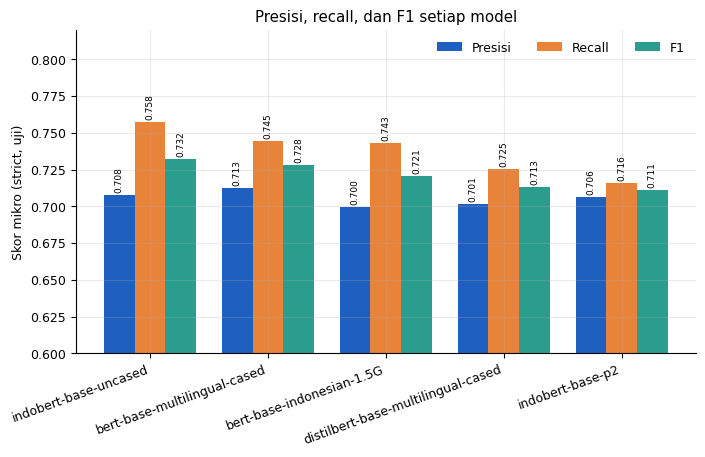

  ✓ outputs/figures_benchmark/B1_prf_per_model.png


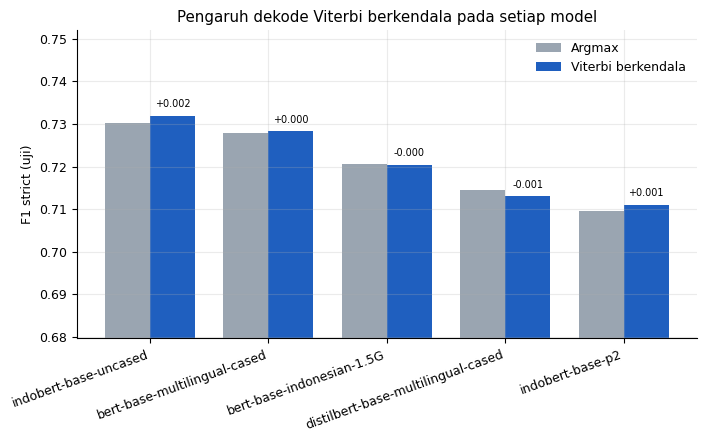

  ✓ outputs/figures_benchmark/B2_argmax_vs_viterbi.png


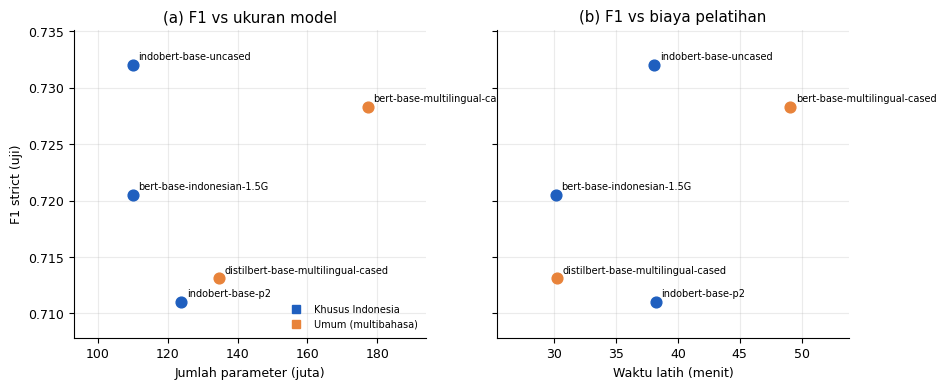

  ✓ outputs/figures_benchmark/B3_f1_vs_biaya.png


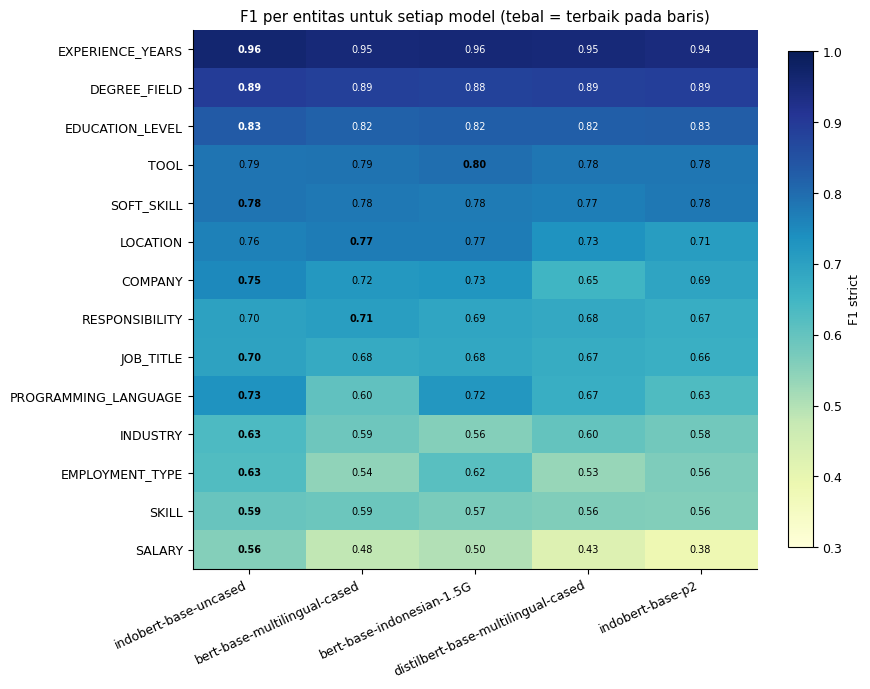

  ✓ outputs/figures_benchmark/B4_heatmap_per_entitas.png


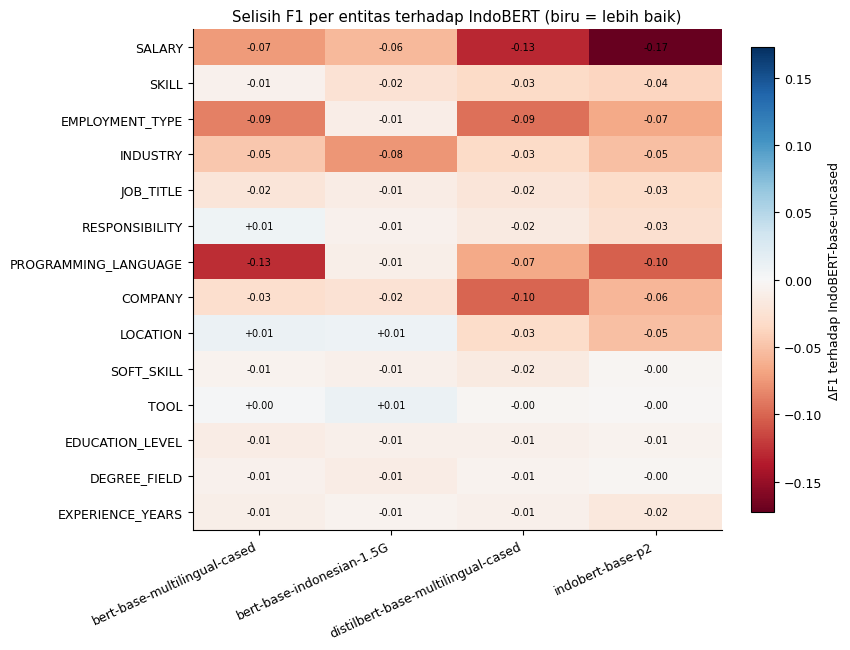

  ✓ outputs/figures_benchmark/B5_selisih_terhadap_indobert.png


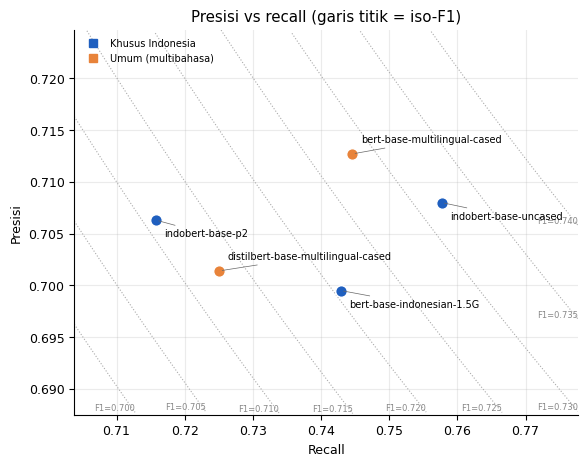

  ✓ outputs/figures_benchmark/B6_presisi_vs_recall.png


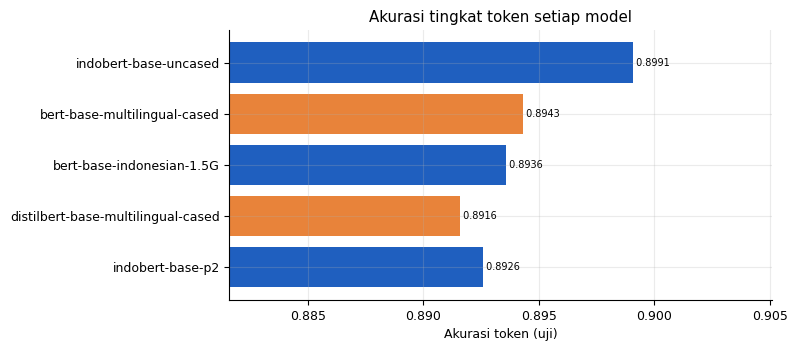

  ✓ outputs/figures_benchmark/B7_akurasi_token.png


In [15]:
@aman
def B1_prf_per_model():
    nm = [PENDEK[h["model"]] for h in HB]; x = np.arange(len(HB)); w = .26
    fig, ax = plt.subplots(figsize=(8, 4.2))
    for j, (k, lab, c) in enumerate([("presisi", "Presisi", "#1f5fbf"), ("recall", "Recall", "#e8833a"), ("f1_viterbi", "F1", "#2a9d8f")]):
        v = [h[k] for h in HB]; ax.bar(x + (j - 1) * w, v, w, label=lab, color=c)
        for xi, vi in zip(x + (j - 1) * w, v): ax.text(xi, vi + .003, f"{vi:.3f}", ha="center", fontsize=6.5, rotation=90)
    ax.set_xticks(x, nm, rotation=20, ha="right"); ax.set_ylim(.6, .82)
    ax.set_ylabel("Skor mikro (strict, uji)"); ax.legend(frameon=False, ncol=3, loc="upper right")
    ax.set_title("Presisi, recall, dan F1 setiap model")
    simpan(fig, "B1_prf_per_model", "P/R/F1 per model")

@aman
def B2_argmax_vs_viterbi():
    nm = [PENDEK[h["model"]] for h in HB]; x = np.arange(len(HB)); w = .38
    fig, ax = plt.subplots(figsize=(8, 4))
    a = [h["f1_argmax"] for h in HB]; v = [h["f1_viterbi"] for h in HB]
    ax.bar(x - w/2, a, w, color="#9aa5b1", label="Argmax"); ax.bar(x + w/2, v, w, color="#1f5fbf", label="Viterbi berkendala")
    for xi, ai, vi in zip(x, a, v): ax.text(xi + w/2, vi + .002, f"{vi-ai:+.3f}", ha="center", fontsize=7)
    ax.set_xticks(x, nm, rotation=20, ha="right"); ax.set_ylim(min(a) - .03, max(v) + .02)
    ax.set_ylabel("F1 strict (uji)"); ax.legend(frameon=False); ax.set_title("Pengaruh dekode Viterbi berkendala pada setiap model")
    simpan(fig, "B2_argmax_vs_viterbi", "Argmax vs Viterbi per model")

@aman
def B3_f1_vs_biaya():
    fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
    for h in HB:
        for k, (kol, xl) in enumerate([("parameter_juta", "Jumlah parameter (juta)"), ("menit", "Waktu latih (menit)")]):
            ax[k].scatter(h[kol], h["f1_viterbi"], s=60, color=warna(h["model"]), zorder=3)
            ax[k].annotate(PENDEK[h["model"]], (h[kol], h["f1_viterbi"]), xytext=(4, 4), textcoords="offset points", fontsize=7)
            ax[k].set_xlabel(xl)
    for a in ax: a.margins(x=.25, y=.15)
    ax[0].set_ylabel("F1 strict (uji)"); ax[0].legend(handles=LEG, frameon=False, fontsize=7, loc="lower right")
    ax[0].set_title("(a) F1 vs ukuran model"); ax[1].set_title("(b) F1 vs biaya pelatihan")
    simpan(fig, "B3_f1_vs_biaya", "F1 vs parameter dan waktu latih")

def _per_ent():
    return pd.DataFrame({PENDEK[h["model"]]: {e: h["per_entitas"].get(e, {}).get("f1", np.nan) for e in CFG.ENTITY_LABELS} for h in HB})

@aman
def B4_heatmap_per_entitas():
    P = _per_ent(); P = P.loc[P.mean(axis=1).sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(P.values, cmap="YlGnBu", vmin=.3, vmax=1, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(P.shape[1]), P.columns, rotation=25, ha="right"); ax.set_yticks(range(P.shape[0]), P.index)
    best = P.values.argmax(axis=1)
    for i in range(P.shape[0]):
        for j in range(P.shape[1]):
            ax.text(j, i, f"{P.values[i,j]:.2f}", ha="center", va="center", fontsize=7,
                    fontweight="bold" if j == best[i] else "normal", color="white" if P.values[i, j] > .8 else "black")
    fig.colorbar(im, ax=ax, fraction=.04, label="F1 strict")
    ax.set_title("F1 per entitas untuk setiap model (tebal = terbaik pada baris)")
    simpan(fig, "B4_heatmap_per_entitas", "Heatmap F1 per entitas × model")

@aman
def B5_selisih_terhadap_indobert():
    P = _per_ent(); acuan = next(c for c in P.columns if "indobert-base-uncased" in c)
    D = P.drop(columns=acuan).sub(P[acuan], axis=0)
    D = D.loc[P[acuan].sort_values().index]
    lim = np.nanmax(np.abs(D.values))
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    im = ax.imshow(D.values, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(D.shape[1]), D.columns, rotation=25, ha="right"); ax.set_yticks(range(D.shape[0]), D.index)
    for i in range(D.shape[0]):
        for j in range(D.shape[1]): ax.text(j, i, f"{D.values[i,j]:+.2f}", ha="center", va="center", fontsize=7)
    fig.colorbar(im, ax=ax, fraction=.04, label="ΔF1 terhadap IndoBERT-base-uncased")
    ax.set_title("Selisih F1 per entitas terhadap IndoBERT (biru = lebih baik)")
    simpan(fig, "B5_selisih_terhadap_indobert", "Selisih F1 per entitas terhadap IndoBERT")

@aman
def B6_presisi_vs_recall():
    rs = [h["recall"] for h in HB]; ps = [h["presisi"] for h in HB]
    x0, x1 = min(rs) - .012, max(rs) + .02; y0, y1 = min(ps) - .012, max(ps) + .012
    fig, ax = plt.subplots(figsize=(6.5, 5))
    r = np.linspace(x0, x1, 200)
    fs = np.round(np.arange(np.floor((min(h["f1_viterbi"] for h in HB) - .01) * 200) / 200, max(h["f1_viterbi"] for h in HB) + .011, .005), 3)
    for f in fs:
        p = f * r / (2 * r - f); ok = (p > y0) & (p < y1)
        if ok.sum() > 2:
            ax.plot(r[ok], p[ok], ls=":", color="#aaa", lw=.8)
            ax.text(r[ok][-1], p[ok][-1], f"F1={f:.3f}", fontsize=6, color="#888", ha="right", va="bottom")
    for k, h in enumerate(sorted(HB, key=lambda h: h["recall"])):
        ax.scatter(h["recall"], h["presisi"], s=70, color=warna(h["model"]), zorder=3, edgecolor="white")
        ax.annotate(PENDEK[h["model"]], (h["recall"], h["presisi"]), xytext=(6, 8 if k % 2 else -12),
                    textcoords="offset points", fontsize=7, arrowprops=dict(arrowstyle="-", lw=.5, color="#666"))
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)
    ax.set_xlabel("Recall"); ax.set_ylabel("Presisi"); ax.legend(handles=LEG, frameon=False, fontsize=7, loc="upper left")
    ax.set_title("Presisi vs recall (garis titik = iso-F1)")
    simpan(fig, "B6_presisi_vs_recall", "Presisi vs recall per model")

@aman
def B7_akurasi_token():
    nm = [PENDEK[h["model"]] for h in HB]; v = [h["akurasi_token"] for h in HB]
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.barh(nm[::-1], v[::-1], color=[warna(h["model"]) for h in HB][::-1])
    for i, x in enumerate(v[::-1]): ax.text(x, i, f" {x:.4f}", va="center", fontsize=7)
    ax.set_xlim(min(v) - .01, max(v) + .006); ax.set_xlabel("Akurasi token (uji)")
    ax.set_title("Akurasi tingkat token setiap model")
    simpan(fig, "B7_akurasi_token", "Akurasi token per model")


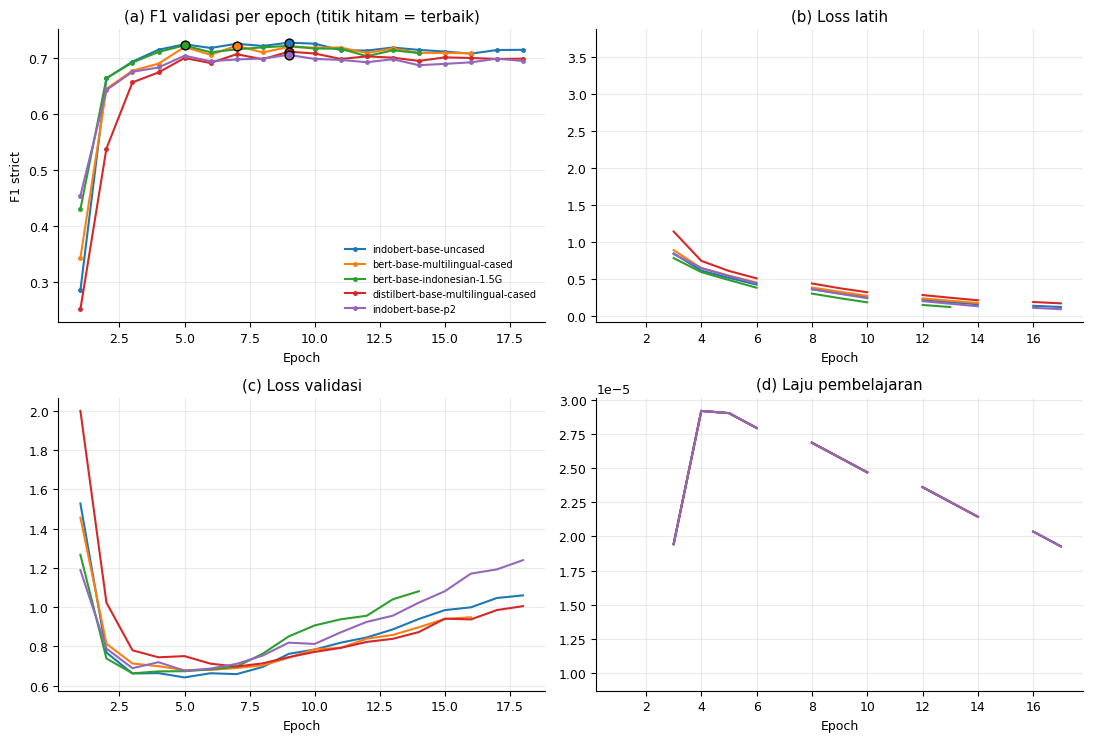

  ✓ outputs/figures_benchmark/B8_kurva_pelatihan_semua_model.png


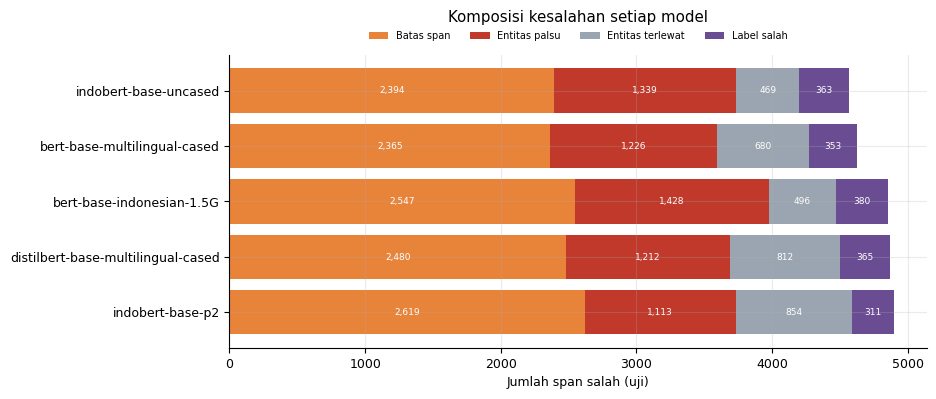

  ✓ outputs/figures_benchmark/B9_jenis_kesalahan_per_model.png
  – hasil_multiseed.json belum ada (bagian 7 nonaktif).

9 grafik tersimpan di outputs/figures_benchmark/


,berkas,keterangan
0,B1_prf_per_model,P/R/F1 per model
1,B2_argmax_vs_viterbi,Argmax vs Viterbi per model
2,B3_f1_vs_biaya,F1 vs parameter dan waktu latih
3,B4_heatmap_per_entitas,Heatmap F1 per entitas × model
4,B5_selisih_terhadap_indobert,Selisih F1 per entitas terhadap IndoBERT
5,B6_presisi_vs_recall,Presisi vs recall per model
6,B7_akurasi_token,Akurasi token per model
7,B8_kurva_pelatihan_semua_model,Kurva pelatihan seluruh model
8,B9_jenis_kesalahan_per_model,Jenis kesalahan per model


'/kaggle/working/outputs/grafik_benchmark.zip'

In [16]:
def _riwayat(h):
    """Riwayat per epoch: dari hasil v2, atau dari trainer_state.json checkpoint terakhir."""
    if h.get("riwayat"): return pd.DataFrame(h["riwayat"])
    pola = f"{CFG.OUTPUT_DIR}/tmp_{h['model'].replace('/', '_')}_{h.get('seed', CFG.SEED)}/checkpoint-*/trainer_state.json"
    cand = sorted(glob.glob(pola), key=lambda p: int(p.split("checkpoint-")[1].split("/")[0]))
    if not cand: return None
    log = json.load(open(cand[-1]))["log_history"]
    rows = {}
    for r in log:
        ep = round(float(r.get("epoch", 0))); e = rows.setdefault(ep, {"epoch": ep})
        if "loss" in r: e.setdefault("_l", []).append(r["loss"])
        for k in ("eval_loss", "eval_f1", "learning_rate"):
            if k in r: e[k] = r[k]
    for e in rows.values():
        if "_l" in e: e["train_loss"] = float(np.mean(e.pop("_l")))
    return pd.DataFrame([rows[k] for k in sorted(rows)])

@aman
def B8_kurva_pelatihan_semua_model():
    R = {PENDEK[h["model"]]: (_riwayat(h), h["model"]) for h in HB}
    R = {k: v for k, v in R.items() if v[0] is not None and len(v[0])}
    if not R:
        print("  – belum ada riwayat per epoch (hasil lama). Hapus hasil_benchmark.json lalu jalankan ulang bagian 6."); return
    fig, ax = plt.subplots(2, 2, figsize=(11, 7.5))
    cm = plt.cm.tab10
    for i, (nm, (df, m)) in enumerate(R.items()):
        c = cm(i)
        if "eval_f1" in df:
            ax[0, 0].plot(df["epoch"], df["eval_f1"], marker="o", ms=2.5, color=c, label=nm)
            b = df["eval_f1"].idxmax(); ax[0, 0].scatter(df.loc[b, "epoch"], df.loc[b, "eval_f1"], s=40, color=c, edgecolor="k", zorder=4)
        if "train_loss" in df: ax[0, 1].plot(df["epoch"], df["train_loss"], color=c, label=nm)
        if "eval_loss" in df: ax[1, 0].plot(df["epoch"], df["eval_loss"], color=c, label=nm)
        if "learning_rate" in df: ax[1, 1].plot(df["epoch"], df["learning_rate"], color=c, label=nm)
    ax[0, 0].set_title("(a) F1 validasi per epoch (titik hitam = terbaik)"); ax[0, 0].set_ylabel("F1 strict")
    ax[0, 1].set_title("(b) Loss latih"); ax[1, 0].set_title("(c) Loss validasi"); ax[1, 1].set_title("(d) Laju pembelajaran")
    ax[1, 1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    for a in ax.flat: a.set_xlabel("Epoch")
    ax[0, 0].legend(frameon=False, fontsize=7)
    fig.tight_layout()
    simpan(fig, "B8_kurva_pelatihan_semua_model", "Kurva pelatihan seluruh model")

@aman
def B9_jenis_kesalahan_per_model():
    H = [h for h in HB if h.get("kesalahan")]
    if not H: print("  – belum ada data jenis kesalahan (hasil lama). Jalankan ulang bagian 6 dengan notebook v2."); return
    kat = [("batas", "Batas span", "#e8833a"), ("palsu", "Entitas palsu", "#c0392b"), ("terlewat", "Entitas terlewat", "#9aa5b1"), ("salah_label", "Label salah", "#6a4c93")]
    nm = [PENDEK[h["model"]] for h in H]; kiri = np.zeros(len(H))
    fig, ax = plt.subplots(figsize=(9, 3.8))
    for k, lab, c in kat:
        v = np.array([h["kesalahan"].get(k, 0) for h in H]); ax.barh(nm, v, left=kiri, color=c, label=lab)
        for i, (l, x) in enumerate(zip(kiri, v)):
            if x > 150: ax.text(l + x/2, i, f"{x:,}", ha="center", va="center", fontsize=6.5, color="white")
        kiri += v
    ax.invert_yaxis(); ax.set_xlabel("Jumlah span salah (uji)"); ax.legend(frameon=False, ncol=4, fontsize=7, loc="lower center", bbox_to_anchor=(.5, 1.02))
    ax.set_title("Komposisi kesalahan setiap model", pad=24)
    simpan(fig, "B9_jenis_kesalahan_per_model", "Jenis kesalahan per model")

@aman
def B10_multiseed():
    p = f"{CFG.OUTPUT_DIR}/hasil_multiseed.json"
    if not os.path.exists(p): print("  – hasil_multiseed.json belum ada (bagian 7 nonaktif)."); return
    d = pd.DataFrame([{"model": PENDEK.get(h["model"], h["model"]), "f1": h["f1_viterbi"]} for h in json.load(open(p))])
    urut = d.groupby("model")["f1"].mean().sort_values().index.tolist()
    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.boxplot([d.loc[d.model == m, "f1"] for m in urut], tick_labels=urut, orientation="horizontal")
    for i, m in enumerate(urut, 1):
        v = d.loc[d.model == m, "f1"]; ax.scatter(v, np.full(len(v), i), s=14, color="#1f5fbf", zorder=3)
    ax.set_xlabel("F1 strict (uji)"); ax.set_title("Sebaran F1 antar-seed")
    simpan(fig, "B10_multiseed", "Sebaran F1 antar-seed")

print(f"\n{len(DAFTAR_GB)} grafik tersimpan di {FIGB}/")
display(pd.DataFrame(DAFTAR_GB, columns=["berkas", "keterangan"]))
import shutil; shutil.make_archive(f"{CFG.OUTPUT_DIR}/grafik_benchmark", "zip", FIGB)


## 9. Catatan untuk penulisan naskah

**Selisih kecil bukan bukti keunggulan.** Pelatihan pada GPU tidak identik
antar-eksekusi meski seed sama; dua eksekusi pipeline yang sama pada proyek
ini berselisih sekitar 0,008 F1. Bila model terbaik hanya unggul 0,005 dari
IndoBERT, itu masih dalam rentang derau. Untuk klaim yang kuat, jalankan
model teratas dengan tiga seed berbeda (42, 1337, 2024) lalu laporkan
rata-rata dan simpangan bakunya.

**Sebutkan biayanya, bukan hanya skornya.** Model *large* umumnya unggul
sedikit tetapi memerlukan waktu dan memori dua sampai tiga kali lipat. Untuk
skripsi yang menekankan penerapan praktis, perbandingan skor terhadap biaya
komputasi lebih bernilai daripada sekadar mengejar angka tertinggi.

**Cara membaca selisih model khusus vs umum.** Selisih F1 antara IndoBERT dan
mBERT/DistilmBERT menunjukkan seberapa besar manfaat pralatih khusus bahasa
Indonesia untuk teks lowongan kerja. Bila model umum hanya sedikit lebih rendah,
artinya pendekatan ini juga dapat dipakai pada bahasa lain yang tidak punya
model khusus; bila jauh lebih rendah, itu argumen untuk memakai model bahasa
Indonesia. Sertakan juga waktu latih: DistilmBERT jauh lebih ringan.

**Unduh sebelum sesi berakhir**: `outputs/hasil_benchmark.json`,
`outputs/perbandingan_model.csv`, `outputs/perbandingan_per_entitas.csv`, dan
`outputs/tabel_benchmark.tex`. Klik **Save Version** agar isi `outputs/`
tersimpan.
